In [1]:
# 1. Import necessary components from Qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Initialize the simulator backend
simulator = AerSimulator()


In [2]:
# Generates the |ψ+⟩ state where qubits are perfectly correlated (00 and 11)
qc_original = QuantumCircuit(2, 2)
qc_original.h(0)          # Gate 1: Create superposition on Qubit 0
qc_original.cx(0, 1)      # Gate 2: Entangle Qubit 0 and Qubit 1
qc_original.measure([0, 1], [0, 1])  # Measure both qubits

# Execute the original circuit for 100 shots
counts_original = simulator.run(qc_original, shots=100).result().get_counts()
print("Original Bell Circuit Counts:", counts_original)

Original Bell Circuit Counts: {'11': 53, '00': 47}


In [3]:
# Generates the |ψ+⟩ Bell state variant where qubits are anti-correlated (01 and 10)
qc_modified = QuantumCircuit(2, 2)
qc_modified.h(0)          # Gate 1: Create superposition on Qubit 0
qc_modified.cx(0, 1)      # Gate 2: Entangle Qubit 0 and Qubit 1
qc_modified.x(1)          # Gate 3 [MODIFICATION]: Flip Qubit 1 (Total gates: 3 <= 4)
qc_modified.measure([0, 1], [0, 1])  # Measure both qubits

# Execute the modified circuit for 100 shots
counts_modified = simulator.run(qc_modified, shots=100).result().get_counts()
print("Modified Circuit Counts:", counts_modified)

Modified Circuit Counts: {'01': 49, '10': 51}


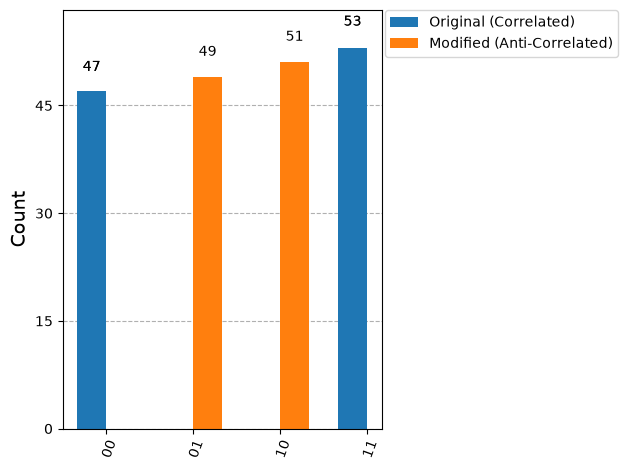

In [4]:
plot_histogram([counts_original, counts_modified], 
               legend=['Original (Correlated)', 'Modified (Anti-Correlated)'])